In [2]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from src.data_processing import load_clean_jobs

clean = load_clean_jobs("../data/processed/clean_jobs.parquet")
print(clean.shape)

(119055, 24)


In [3]:
print("postings:", len(clean))
print("salary disclosed:", clean["salary_disclosed"].sum(), f"({clean['salary_disclosed'].mean():.1%})")
print("no job function:", (clean["job_function"].str.len() == 0).sum())
print("no company industry:", (clean["industry"].str.len() == 0).sum())
print("empty description:", (clean["description_length"] == 0).sum())
print()
print(clean["location_type"].value_counts())

postings: 119055
salary disclosed: 35295 (29.6%)
no job function: 1740
no company industry: 1861
empty description: 6

location_type
city_state      101152
country_only      7802
metro_area        5716
state_name        4385
Name: count, dtype: int64


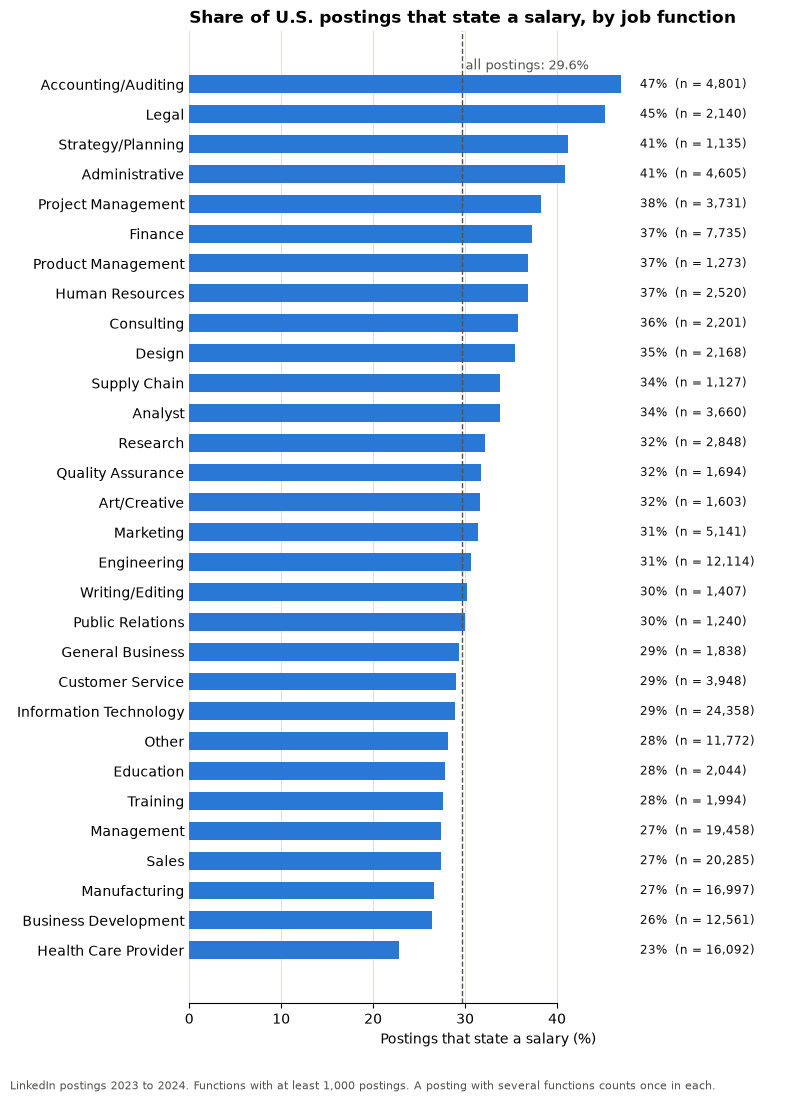

In [7]:
coverage = pd.read_csv("../data/processed/audit_function_coverage.csv", index_col=0)
coverage = coverage[(coverage.index != "(none)") & (coverage["postings"] >= 1000)]
coverage = coverage.sort_values("salary_disclosure_rate")
overall = clean["salary_disclosed"].mean()

max_pct = coverage["salary_disclosure_rate"].max() * 100
label_x = max_pct + 2

fig, ax = plt.subplots(figsize=(8, 0.32 * len(coverage) + 1.4))

# Bars and the overall reference line
ax.barh(coverage.index, coverage["salary_disclosure_rate"] * 100, color="#2a78d6", height=0.6)
ax.axvline(overall * 100, color="#52514e", linestyle="--", linewidth=1)
ax.text(overall * 100 + 0.4, len(coverage) - 0.5, f"all postings: {overall:.1%}",
        color="#52514e", fontsize=9)

# Value labels in one column to the right of the longest bar
for y, (rate, n) in enumerate(zip(coverage["salary_disclosure_rate"], coverage["postings"])):
    ax.text(label_x, y, f"{rate:.0%}  (n = {n:,})", va="center", fontsize=8.5, color="#0b0b0b")

# Axes and text
ax.set_xlim(0, label_x + 16)
ax.set_xticks(range(0, int(max_pct) + 1, 10))
ax.set_xlabel("Postings that state a salary (%)")
ax.set_title("Share of U.S. postings that state a salary, by job function",
             loc="left", fontsize=12, fontweight="bold")
fig.text(0.01, 0.005, "LinkedIn postings 2023 to 2024. Functions with at least 1,000 postings. "
         "A posting with several functions counts once in each.", fontsize=8, color="#52514e")

# Clean look
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines["bottom"].set_bounds(0, 40)
fig.tight_layout(rect=(0, 0.03, 1, 1))

fig.savefig("../figures/salary_disclosure_by_function.png", dpi=200, bbox_inches="tight")
plt.show()